# 连续力矩与价值估计 / Pendulum Actor-Critic

摆杆向右倾斜时，动作不再只有“左”和“右”，还包括力矩的大小。
Pendulum 的动作是 −2 到 2 的一个数。我们先记录不施力时的轨迹，再训练高斯策略和价值网络。

本实验复用书中 A2C + VecNormalize 配方，默认 CPU、8 个环境、100,000 步。
可将 `TOTAL_STEPS` 改为 300000 继续训练。
对应源码：`code/chapter06_actor_critic/actor_critic_pendulum.py`。


In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4", "PIL": "pillow>=10,<13",
            "gymnasium": "gymnasium[classic-control]>=1.0,<2", "pygame": "pygame>=2.5,<3",
            "stable_baselines3": "stable-baselines3>=2.4,<3"}
missing = [spec for name, spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import os
from pathlib import Path

os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from stable_baselines3 import A2C
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

torch.set_num_threads(1)
OUTPUT = Path(os.getenv("HANDS_ON_LAB_OUTPUT", "lab-output")) / "pendulum"
OUTPUT.mkdir(parents=True, exist_ok=True)
TOTAL_STEPS, SEED = 100000, 42
probe = gym.make("Pendulum-v1")
obs, _ = probe.reset(seed=SEED)
print({"observation": obs.tolist(), "torque_range": [-2, 2], "steps": TOTAL_STEPS})
assert obs.shape == (3,) and probe.action_space.shape == (1,)
probe.close()


{'observation': [-0.14995256066322327, 0.9886931777000427, -0.12224312126636505], 'torque_range': [-2, 2], 'steps': 100000}


## 1. 评估必须使用训练时的观测统计 / Normalization

观测是角度的余弦、正弦和角速度。训练时将观测、奖励归一化，价值网络因而预测归一化回报。
评估保留观测统计、关闭统计更新，并累计环境原始奖励。
下面固定使用 1,000–1,009 的评估种子，训练过程不会接触这些初始状态。


In [2]:
def make_env(rank):
    def create():
        env = Monitor(gym.make("Pendulum-v1"))
        env.reset(seed=SEED + rank)
        return env
    return create


train_env = VecNormalize(DummyVecEnv([make_env(i) for i in range(8)]),
                         norm_obs=True, norm_reward=True)
model = A2C("MlpPolicy", train_env, n_steps=32, learning_rate=7e-4,
            gae_lambda=0.95, gamma=0.99, seed=SEED, device="cpu", verbose=0)


@torch.no_grad()
def evaluate(policy=None):
    env = gym.make("Pendulum-v1")
    totals = []
    for seed in range(1000, 1010):
        obs, _ = env.reset(seed=seed)
        total = 0.0
        for _ in range(200):
            action = np.zeros(1) if policy is None else policy.predict(
                train_env.normalize_obs(obs[None]), deterministic=True)[0][0]
            obs, reward, terminated, truncated, _ = env.step(action)
            total += reward
            if terminated or truncated:
                break
        totals.append(total)
    env.close()
    return totals


zero_return, before = evaluate(), evaluate(model)
print("Zero torque / untrained mean:", np.mean(zero_return), np.mean(before))


class Record(BaseCallback):
    def __init__(self):
        super().__init__()
        self.rewards, self.curve = [], [(0, float(np.mean(before)))]
        self.losses = []

    def _on_step(self):
        self.rewards.extend(info["episode"]["r"] for info in self.locals["infos"]
                            if "episode" in info)
        if self.num_timesteps % 20000 == 0:
            self.curve.append((self.num_timesteps, float(np.mean(evaluate(self.model)))))
            self.losses.append(float(self.model.logger.name_to_value.get("train/value_loss", 0)))
        return True


record = Record()
model.learn(total_timesteps=TOTAL_STEPS, callback=record)
after = evaluate(model)
print("Held-out return before / after:", np.mean(before), np.mean(after))
assert np.isfinite(after).all() and len(record.rewards) > 0


Zero torque / untrained mean: -1309.083083455785 -1313.4932457569505


Held-out return before / after: -1313.4932457569505 -1245.1743549325186


## 2. 同时保存模型和统计量 / Save and reload

只保存网络会丢失输入的归一化方式。我们同时保存网络和统计量，重新加载后检查同一观测的动作。
曲线比较同一组评估种子上的基线回报与训练后回报。


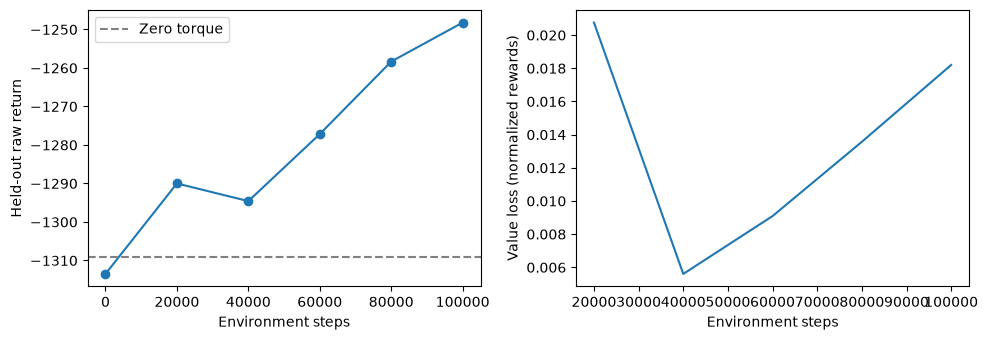

In [3]:
model.save(OUTPUT / "a2c")
train_env.save(OUTPUT / "normalization.pkl")
reloaded_env = VecNormalize.load(OUTPUT / "normalization.pkl",
                                DummyVecEnv([make_env(100)]))
reloaded_env.training, reloaded_env.norm_reward = False, False
reloaded = A2C.load(OUTPUT / "a2c", env=reloaded_env, device="cpu")
obs = np.array([[1.0, 0.0, 0.3]], dtype=np.float32)
assert np.allclose(model.predict(train_env.normalize_obs(obs), deterministic=True)[0],
                   reloaded.predict(reloaded_env.normalize_obs(obs), deterministic=True)[0])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
curve = np.array(record.curve)
axes[0].plot(curve[:, 0], curve[:, 1], marker="o")
axes[0].axhline(np.mean(zero_return), ls="--", color="grey", label="Zero torque")
axes[0].set(xlabel="Environment steps", ylabel="Held-out raw return")
axes[0].legend()
axes[1].plot(curve[1:, 0], record.losses)
axes[1].set(xlabel="Environment steps", ylabel="Value loss (normalized rewards)")
fig.tight_layout()
fig.savefig(OUTPUT / "training.png", dpi=120)
plt.show()


## 3. 检查力矩与摆杆回放 / A fixed-seed replay

回放使用新种子 2,000，模型通过冻结的观测统计处理输入。
每一步的力矩、角速度和价值预测都来自当前模型。图中价值的单位与原始奖励不同。


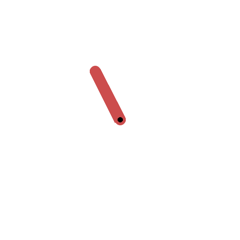

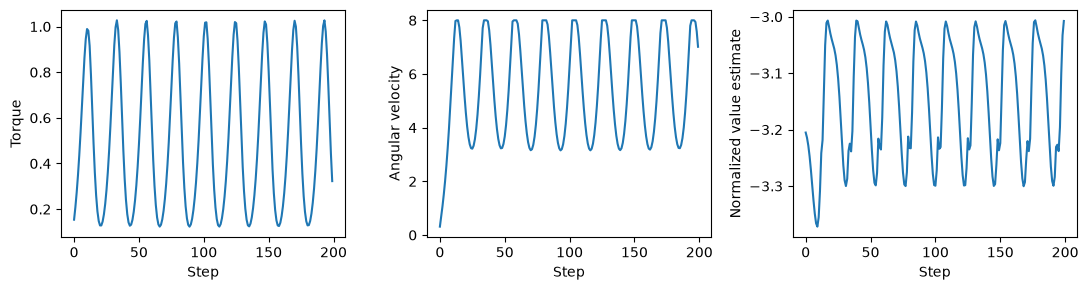

In [4]:
from IPython.display import Image, display
from PIL import Image as PILImage

env = gym.make("Pendulum-v1", render_mode="rgb_array")
obs, _ = env.reset(seed=2000)
frames, actions, speeds, values = [], [], [], []
for step in range(200):
    normalized = reloaded_env.normalize_obs(obs[None])
    action, _ = reloaded.predict(normalized, deterministic=True)
    with torch.no_grad():
        value = reloaded.policy.predict_values(torch.tensor(normalized)).item()
    actions.append(float(action[0, 0]))
    speeds.append(float(obs[2]))
    values.append(value)
    if step % 2 == 0:
        frames.append(PILImage.fromarray(env.render()).resize((240, 240)))
    obs, _, terminated, truncated, _ = env.step(action[0])
    if terminated or truncated:
        break
env.close()
assert np.max(np.abs(actions)) <= 2
frames[0].save(OUTPUT / "policy.gif", save_all=True, append_images=frames[1:], duration=100, loop=0)
display(Image(filename=str(OUTPUT / "policy.gif")))
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, data, label in zip(axes, [actions, speeds, values],
                          ["Torque", "Angular velocity", "Normalized value estimate"]):
    ax.plot(data)
    ax.set(xlabel="Step", ylabel=label)
fig.tight_layout()
fig.savefig(OUTPUT / "replay-signals.png", dpi=120)
plt.show()
metrics = {"zero_torque_returns": zero_return, "before_returns": before, "after_returns": after}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
train_env.close()
reloaded_env.close()


## 完成检查 / Checklist
- [ ] 能说明高斯策略与离散动作策略的输出区别。
- [ ] 保存并重新加载了模型和观测统计，通过动作一致性检查。
- [ ] 用环境原始奖励评价策略，并查看摆杆回放。

## 练习 / Exercise
填入评估时是否应更新观测统计。提示：评估过程应使用固定的训练统计量。


In [5]:
RUN_EXERCISE = False
answer = None
if RUN_EXERCISE:
    assert answer is False
else:
    print("Optional exercise: fill answer and enable RUN_EXERCISE.")


Optional exercise: fill answer and enable RUN_EXERCISE.


## 参考资料 / References
- [SB3 A2C](https://stable-baselines3.readthedocs.io/en/master/modules/a2c.html)：
  观察 A2C 的实现接口和连续策略配置。
- [SB3 VecNormalize](https://stable-baselines3.readthedocs.io/en/master/guide/vec_envs.html#vecnormalize)：
  保存、加载及冻结归一化统计量。
- [Pendulum](https://gymnasium.farama.org/environments/classic_control/pendulum/)：
  核对观测、力矩范围和环境奖励。


## 本次运行结果

CPU · Python 3.12.13 · 6.09 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/pendulum-zh.html)
